# NOTEBOOK : 09_evaluation.ipynb
# ROLE     : Final one-time evaluation of baselines, all 5 models, and Stacking on test.csv + live_2026.csv.
# INPUT    : ../../data/processed/{train,test,live_2026}.csv, ../artifacts/models/*.joblib
# OUTPUT   : ../artifacts/metrics.json, ../artifacts/top_features.json, ../reports/figures/*.png

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost

from sklearn.metrics import (
    log_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    root_mean_squared_error,
    confusion_matrix,
)

PROCESSED_DIR = Path("../../data/processed")
ARTIFACTS_DIR = Path("../artifacts")
MODELS_DIR = ARTIFACTS_DIR / "models"
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")
live_df = pd.read_csv(PROCESSED_DIR / "live_2026.csv")

with open(ARTIFACTS_DIR / "features_list.json", "r", encoding="utf-8") as f:
    FEATURE_COLS = json.load(f)

scaler = joblib.load(MODELS_DIR / "match_scaler.joblib")

X_test = test_df[FEATURE_COLS]
X_test_scaled = scaler.transform(X_test)
y_test = test_df["target"].values
y_test_onehot = np.eye(3)[y_test]

print(f"Test set: {len(test_df)} matches | Live 2026-27 set: {len(live_df)} matches")

Test set: 260 matches | Live 2026-27 set: 70 matches


In [2]:
def compute_metrics(y_true, y_pred, y_prob):
    y_true_oh = np.eye(3)[y_true]
    class_recalls = recall_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    return {
        "log_loss": round(float(log_loss(y_true, y_prob, labels=[0, 1, 2])), 4),
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "precision_macro": round(float(precision_score(y_true, y_pred, average="macro", zero_division=0)), 4),
        "recall_macro": round(float(recall_score(y_true, y_pred, average="macro", zero_division=0)), 4),
        "f1_macro": round(float(f1_score(y_true, y_pred, average="macro", zero_division=0)), 4),
        "draw_recall": round(float(class_recalls[1]), 4),
        "mse": round(float(mean_squared_error(y_true_oh, y_prob)), 4),
        "rmse": round(float(root_mean_squared_error(y_true_oh, y_prob)), 4),
    }

# Baseline 1: Always predict Home Win (class 2)
b1_pred = np.full(len(y_test), 2)
b1_prob = np.tile([0.0, 0.0, 1.0], (len(y_test), 1))
baseline_home = compute_metrics(y_test, b1_pred, b1_prob)

# Baseline 2: Historical class frequencies from train.csv
train_freqs = train_df["target"].value_counts(normalize=True).sort_index().values  # [P_A, P_D, P_H]
b2_prob = np.tile(train_freqs, (len(y_test), 1))
b2_pred = np.full(len(y_test), int(np.argmax(train_freqs)))
baseline_freq = compute_metrics(y_test, b2_pred, b2_prob)

print("Baseline 1 (Always Home Win) :", baseline_home)
print("Baseline 2 (Train Class Freq):", baseline_freq)

Baseline 1 (Always Home Win) : {'log_loss': 21.7648, 'accuracy': 0.3962, 'precision_macro': 0.1321, 'recall_macro': 0.3333, 'f1_macro': 0.1892, 'draw_recall': 0.0, 'mse': 0.4026, 'rmse': 0.6253}
Baseline 2 (Train Class Freq): {'log_loss': 1.1029, 'accuracy': 0.3962, 'precision_macro': 0.1321, 'recall_macro': 0.3333, 'f1_macro': 0.1892, 'draw_recall': 0.0, 'mse': 0.2227, 'rmse': 0.4717}


In [3]:
MODEL_CONFIGS = [
    ("logistic_regression", True),
    ("decision_tree", False),
    ("random_forest", False),
    ("gradient_boosting", False),
    ("xgboost", False),
]

test_results = []
predictions_store = {}

# 1. Individual models
for name, use_scaled in MODEL_CONFIGS:
    model = joblib.load(MODELS_DIR / f"{name}.joblib")
    X_in = X_test_scaled if use_scaled else X_test
    y_prob = model.predict_proba(X_in)
    y_pred = model.predict(X_in)

    metrics = compute_metrics(y_test, y_pred, y_prob)
    test_results.append({"model": name, **metrics})
    predictions_store[name] = (y_pred, y_prob)

# 2. Stacking model
stack_art = joblib.load(MODELS_DIR / "stacking_model.joblib")
X_t1 = X_test_scaled if stack_art["model_1_uses_scaled"] else X_test
X_t2 = X_test_scaled if stack_art["model_2_uses_scaled"] else X_test

meta_X_test = np.hstack([
    stack_art["model_1"].predict_proba(X_t1),
    stack_art["model_2"].predict_proba(X_t2),
])
stack_prob = stack_art["meta_model"].predict_proba(meta_X_test)
stack_pred = stack_art["meta_model"].predict(meta_X_test)

stack_metrics = compute_metrics(y_test, stack_pred, stack_prob)
test_results.append({"model": "stacking", **stack_metrics})
predictions_store["stacking"] = (stack_pred, stack_prob)

test_results_df = pd.DataFrame(test_results).sort_values("log_loss", ascending=True).reset_index(drop=True)
test_results_df.index = test_results_df.index + 1
test_results_df.index.name = "rank"

display(test_results_df)

,model,log_loss,accuracy,precision_macro,recall_macro,f1_macro,draw_recall,mse,rmse
rank,,,,,,,,,
1,stacking,1.0793,0.4385,0.2919,0.3994,0.3273,0.0000,0.2177,0.4665
2,logistic_regression,1.0949,0.4231,0.2770,0.3904,0.3222,0.0000,0.2203,0.4693
3,random_forest,1.0981,0.4192,0.2729,0.3862,0.3177,0.0000,0.2211,0.4701
4,decision_tree,1.1152,0.4346,0.4493,0.4051,0.3397,0.0128,0.2256,0.4750
5,xgboost,1.1183,0.4038,0.4078,0.3754,0.3271,0.0385,0.2246,0.4738
6,gradient_boosting,1.1210,0.3923,0.3342,0.3626,0.3123,0.0256,0.2257,0.4750


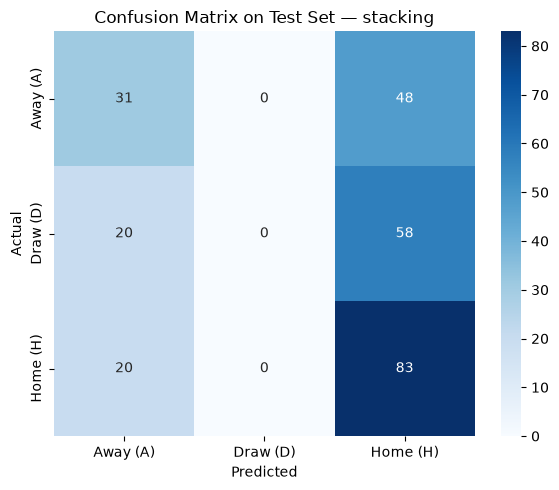

Saved confusion matrix to ..\reports\figures\confusion_matrix_stacking.png


In [4]:
winner_name = test_results_df.iloc[0]["model"]
winner_pred, winner_prob = predictions_store[winner_name]

cm = confusion_matrix(y_test, winner_pred, labels=[0, 1, 2])
labels = ["Away (A)", "Draw (D)", "Home (H)"]

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion Matrix on Test Set — {winner_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

cm_path = FIGURES_DIR / f"confusion_matrix_{winner_name}.png"
plt.savefig(cm_path, dpi=150)
plt.show()
print(f"Saved confusion matrix to {cm_path}")

C:\Users\pc\AppData\Local\Temp\ipykernel_17272\2524968688.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df.head(10), x="mean_importance", y="feature", palette="viridis")


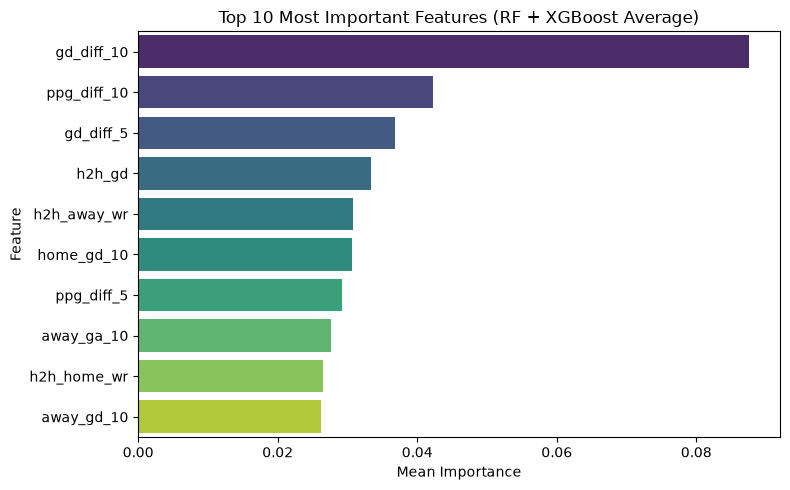

Saved top features to ..\artifacts\top_features.json and plot to ..\reports\figures\top_feature_importances.png


In [5]:
rf_model = joblib.load(MODELS_DIR / "random_forest.joblib")
xgb_model = joblib.load(MODELS_DIR / "xgboost.joblib")

fi_df = pd.DataFrame({
    "feature": FEATURE_COLS,
    "rf_importance": rf_model.feature_importances_,
    "xgb_importance": xgb_model.feature_importances_,
})
fi_df["mean_importance"] = (fi_df["rf_importance"] + fi_df["xgb_importance"]) / 2
fi_df = fi_df.sort_values("mean_importance", ascending=False).reset_index(drop=True)

top_10_features = fi_df.head(10).to_dict(orient="records")
top_features_path = ARTIFACTS_DIR / "top_features.json"
with open(top_features_path, "w", encoding="utf-8") as f:
    json.dump(top_10_features, f, indent=2)

# Plot Top 10 Feature Importances
plt.figure(figsize=(8, 5))
sns.barplot(data=fi_df.head(10), x="mean_importance", y="feature", palette="viridis")
plt.title("Top 10 Most Important Features (RF + XGBoost Average)")
plt.xlabel("Mean Importance")
plt.ylabel("Feature")
plt.tight_layout()

fi_fig_path = FIGURES_DIR / "top_feature_importances.png"
plt.savefig(fi_fig_path, dpi=150)
plt.show()
print(f"Saved top features to {top_features_path} and plot to {fi_fig_path}")

In [6]:
live_metrics = None
if len(live_df) > 0:
    X_live = live_df[FEATURE_COLS]
    X_live_scaled = scaler.transform(X_live)
    y_live = live_df["target"].values

    if winner_name == "stacking":
        X_l1 = X_live_scaled if stack_art["model_1_uses_scaled"] else X_live
        X_l2 = X_live_scaled if stack_art["model_2_uses_scaled"] else X_live
        meta_X_live = np.hstack([
            stack_art["model_1"].predict_proba(X_l1),
            stack_art["model_2"].predict_proba(X_l2),
        ])
        live_prob = stack_art["meta_model"].predict_proba(meta_X_live)
        live_pred = stack_art["meta_model"].predict(meta_X_live)
    else:
        w_model = joblib.load(MODELS_DIR / f"{winner_name}.joblib")
        w_scaled = dict(MODEL_CONFIGS)[winner_name]
        X_l_in = X_live_scaled if w_scaled else X_live
        live_prob = w_model.predict_proba(X_l_in)
        live_pred = w_model.predict(X_l_in)

    live_metrics = compute_metrics(y_live, live_pred, live_prob)
    print(f"Live 2026-27 ({len(live_df)} matches) — {winner_name}:", live_metrics)

metrics_payload = {
    "evaluated_at_utc": datetime.now(timezone.utc).isoformat(),
    "library_versions": {
        "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
    "test_set_size": int(len(test_df)),
    "live_2026_size": int(len(live_df)),
    "baselines": {
        "always_home_win": baseline_home,
        "train_class_frequencies": baseline_freq,
    },
    "test_model_comparison": test_results_df.to_dict(orient="records"),
    "winning_model_on_test": winner_name,
    "live_2026_metrics": live_metrics,
    "top_features": top_10_features,
}

metrics_path = ARTIFACTS_DIR / "metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

print(f"[SAVED] Full evaluation report -> {metrics_path}")

Live 2026-27 (70 matches) — stacking: {'log_loss': 1.0702, 'accuracy': 0.4143, 'precision_macro': 0.2776, 'recall_macro': 0.3712, 'f1_macro': 0.3073, 'draw_recall': 0.0, 'mse': 0.2155, 'rmse': 0.4639}
[SAVED] Full evaluation report -> ..\artifacts\metrics.json
